# GB wind & solar forecast error analysis

This notebook uses the same snapshot and selection logic as the web app (`monitor/`), so its numbers match the UI.
- **Error = actual − forecast.** A negative error means wind or solar under-delivered, and the shortfall must be bought.
- **Gate** = the latest forecast published *strictly before* 11:00 UK time on D-1 (the GB day-ahead auction).

Sections:
1. January 2026, the original brief
2. Error vs lead time
3. Scope check: why the forecast looks biased
4. Twelve months: seasonality, and how well the out-of-sample bands are calibrated
5. Backtest of MW-to-buy
6. Solar and DGWS
7. Recommendation

In [1]:
import sys; sys.path.insert(0, "..")
from datetime import date
import pandas as pd, matplotlib.pyplot as plt
from monitor import core
from monitor.data import load, latest_revision, rows
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": .3})
D = load()
wind_h, windfor, _ = D["sources"]["windfor"]

def frame(source, mode="gate", h=0):
    a, f, night = D["sources"][source]
    df = pd.DataFrame(core.pairs(a, f, mode, h, night_mw=night))
    df["t"] = pd.to_datetime(df.t); df["month"] = df.t.dt.strftime("%Y-%m")
    return df.set_index("t")

def summary(e, actual):
    return pd.Series({"n": len(e), "MAE": e.abs().mean(), "RMSE": (e**2).mean()**.5, "bias": e.mean(),
                      "P10": e.quantile(.1), "P90": e.quantile(.9), "nMAE %": 100 * e.abs().mean() / actual.mean()}).round(1)

gate = frame("windfor")
print("hours compared:", len(gate), "|", gate.index.min().date(), "→", gate.index.max().date())

hours compared: 9376 | 2025-10-01 → 2026-10-27


## 1. January 2026 (original brief)

In [2]:
jan = gate[gate.month == "2026-01"]
print(jan.publishTime.str[11:16].value_counts().to_dict(), "| lead", jan.leadH.min(), "–", jan.leadH.max(), "h")
summary(jan.error, jan.actual)

{'09:30': 744} | lead 14.5 – 37.5 h


n          744.0
MAE       2122.8
RMSE      2616.7
bias     -1840.3
P10      -4312.4
P90        489.0
nMAE %      18.3
dtype: float64

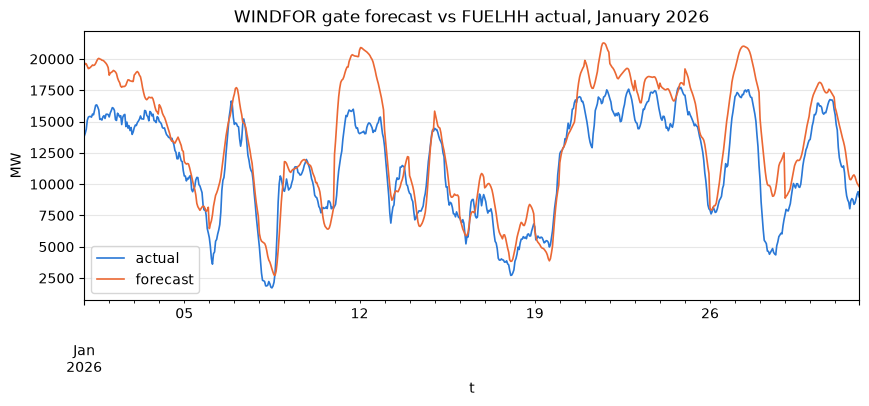

In [3]:
ax = jan[["actual", "forecast"]].plot(color=["#2a78d6", "#eb6834"], lw=1.2)
ax.set_ylabel("MW"); ax.set_title("WINDFOR gate forecast vs FUELHH actual, January 2026");

## 2. Error vs lead time (January 2026)
Horizon mode takes the latest publish at least H hours before the target.

h,0,6,12,18,24,30,36,42,48
mae,1800,1881,1907,1990,2064,2204,2270,2320,2387
rmse,2287,2357,2384,2459,2524,2655,2758,2847,2939
bias,-1593,-1684,-1704,-1791,-1855,-1898,-1951,-1940,-1868
n,744,744,744,744,744,744,744,744,589


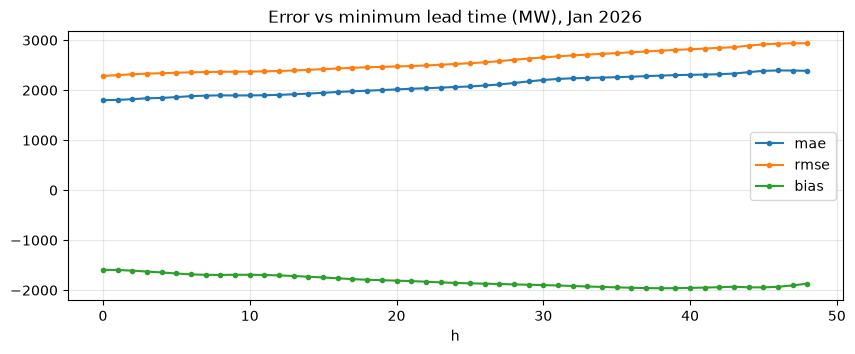

In [4]:
curve = pd.DataFrame(core.horizon_curve(wind_h, windfor, core.ts("2026-01-01T00:00:00Z"), core.ts("2026-01-31T23:00:00Z"))).set_index("h")
curve[["mae", "rmse", "bias"]].plot(marker=".", title="Error vs minimum lead time (MW), Jan 2026"); curve.iloc[::6].round(0).T

Error grows slowly with lead time: about 1.8 GW MAE at 0h, rising to about 2.4 GW at 48h. But even the freshest forecast has a large **bias**, so the next question is where that bias comes from.

## 3. Scope check: why WINDFOR looks biased against FUELHH

In [5]:
ag = latest_revision(rows("agws"))
agws_wind = core.hourly({t: v + ag["wind_off"][t] for t, v in ag["wind_on"].items() if t in ag["wind_off"]})
both = pd.DataFrame({"FUELHH": pd.Series(wind_h), "AGWS": pd.Series(agws_wind)}).dropna()
print(f"mean FUELHH {both.FUELHH.mean():.0f} MW, AGWS {both.AGWS.mean():.0f} MW, gap {(both.AGWS - both.FUELHH).mean():.0f} MW")
dg = D["sources"]["dgws_wind"][1]
grid = {}
for fname, fidx, mode in [("WINDFOR (gate)", windfor, "gate"), ("DGWS (day-ahead run)", dg, "dayahead")]:
    for aname, act in [("vs FUELHH", wind_h), ("vs AGWS", agws_wind)]:
        c = core.core_stats(core.pairs(act, fidx, mode))
        grid[(fname, aname)] = f"MAE {c['mae']:,} / bias {c['bias']:+,}"
pd.Series(grid).unstack()

mean FUELHH 8957 MW, AGWS 10473 MW, gap 1516 MW


,vs AGWS,vs FUELHH
DGWS (day-ahead run),"MAE 2,301 / bias -2,081","MAE 3,597 / bias -3,555"
WINDFOR (gate),"MAE 1,353 / bias +39","MAE 1,797 / bias -1,448"


**Finding.** AGWS wind (which includes an estimate of embedded wind) runs about **1.5 GW above** FUELHH on average over 12 months (FUELHH is transmission-metered only).

Scored against AGWS, WINDFOR's bias almost disappears. So WINDFOR forecasts a **wider wind scope** than FUELHH measures. Most of the apparent January over-forecast is this scope mismatch, not weather error. This supersedes the curtailment hypothesis from the MVP notebook.

**Why it matters for buying.** National Demand (NDF) already nets off embedded generation, so the residual the desk must buy is `NDF − transmission wind`. The app corrects WINDFOR with its trailing median error against **FUELHH**, which re-scales it to transmission scope before subtracting it from NDF. Section 5 backtests this.

## 4. Twelve months: seasonality and band calibration

,MAE,RMSE,bias,P10,P90,nMAE %
month,,,,,,
2025-10,2185.0,2825.0,-1793.0,-4775.0,750.0,24.0
2025-11,1883.0,2375.0,-1009.0,-3874.0,1803.0,17.0
2025-12,2010.0,2563.0,-1405.0,-4375.0,1092.0,18.0
2026-01,2123.0,2617.0,-1840.0,-4312.0,489.0,18.0
2026-02,1683.0,2029.0,-1309.0,-3115.0,580.0,15.0
2026-03,2086.0,2522.0,-1958.0,-3985.0,190.0,21.0
2026-04,1908.0,2592.0,-1557.0,-4754.0,755.0,24.0
2026-05,1160.0,1469.0,-985.0,-2430.0,332.0,19.0
2026-06,1462.0,1882.0,-1174.0,-3212.0,553.0,22.0


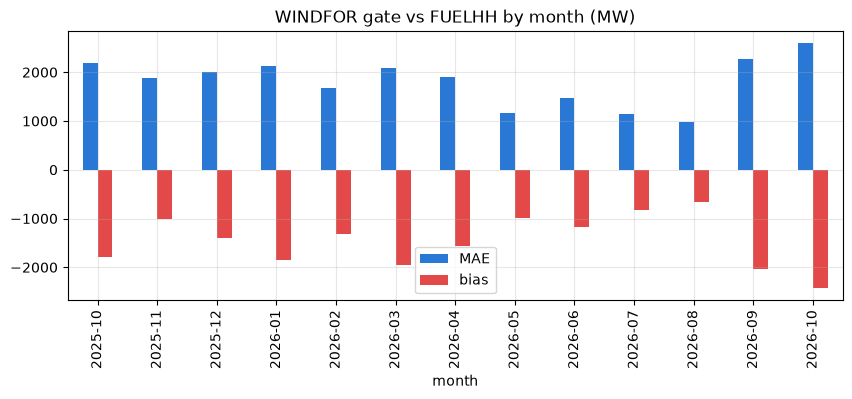

In [6]:
monthly = gate.groupby("month").apply(lambda g: summary(g.error, g.actual)).drop(columns="n")
monthly[["MAE", "bias"]].plot.bar(title="WINDFOR gate vs FUELHH by month (MW)", color=["#2a78d6", "#e34948"]); monthly.round(0)

In [7]:
by_day = core.errors_by_day(core.pairs(wind_h, windfor, "gate"))
bands = {d: core.rolling_band(by_day, date.fromisoformat(d)) for d in gate.day.unique()}
g = gate.assign(p10=gate.day.map(lambda d: (bands[d] or {}).get("p10")), p90=gate.day.map(lambda d: (bands[d] or {}).get("p90"))).dropna()
cov10 = (g.actual >= g.forecast + g.p10).groupby(g.month).mean()
cov90 = (g.actual <= g.forecast + g.p90).groupby(g.month).mean()
cal = pd.DataFrame({"actual ≥ P10 line (target 90%)": cov10, "actual ≤ P90 line (target 90%)": cov90}).round(3) * 100
print(f"overall: {100*(g.actual >= g.forecast + g.p10).mean():.1f}% of hours at or above the conservative P10 line")
cal

overall: 88.4% of hours at or above the conservative P10 line


,actual ≥ P10 line (target 90%),actual ≤ P90 line (target 90%)
month,,
2025-10,99.0,70.5
2025-11,95.0,84.2
2025-12,86.0,90.2
2026-01,88.6,95.3
2026-02,92.9,89.1
2026-03,81.2,92.2
2026-04,89.9,84.6
2026-05,92.3,93.3
2026-06,83.8,89.6


The trailing 30-day band only uses errors known at the gate (days D-31…D-2), so this is a genuine **out-of-sample** check. If a month falls well below 90%, that month's errors were worse than the previous 30 days predicted. This tends to happen when the regime changes (for example, the season turning).

## 5. Backtest: MW-to-buy (portfolio share 5%)

384 days | daily MWh error (actual − expected): MAE 1551, bias +200
conservative covered actual need on 90% of days; average buffer 2784 MWh/day


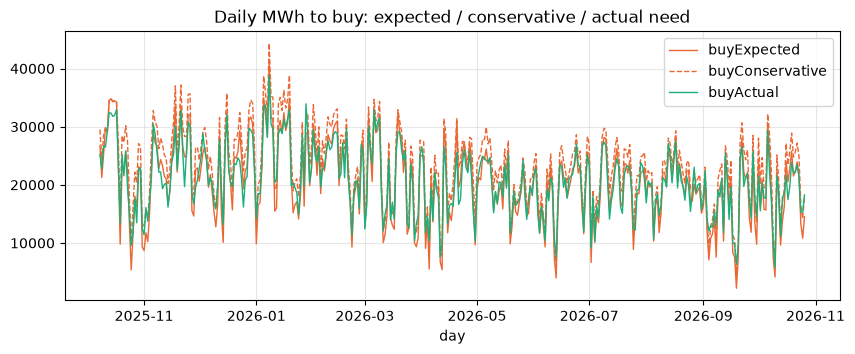

In [8]:
share = 0.05
days = sorted({core.local_day(t) for t in D["ndf"]} & {core.local_day(t) for t in D["nd_actual"]})
recs = []
for d in days:
    dec = core.decision(d, D["ndf"], windfor, core.rolling_band(by_day, d), share, D["nd_actual"], D["wind_hh"])
    t = dec["totals"]
    if None not in t.values() and dec["band"]:
        recs.append({"day": d, **t})
bt = pd.DataFrame(recs).set_index("day")
bt["err_expected"] = bt.buyActual - bt.buyExpected
print(f"{len(bt)} days | daily MWh error (actual − expected): MAE {bt.err_expected.abs().mean():.0f}, bias {bt.err_expected.mean():+.0f}")
print(f"conservative covered actual need on {100*(bt.buyConservative >= bt.buyActual).mean():.0f}% of days; "
      f"average buffer {(bt.buyConservative - bt.buyExpected).mean():.0f} MWh/day")
bt[["buyExpected", "buyConservative", "buyActual"]].plot(title="Daily MWh to buy: expected / conservative / actual need",
                                                         color=["#eb6834", "#eb6834", "#1baf7a"], style=["-", "--", "-"], lw=1);

## 6. Solar and DGWS

In [9]:
sol = frame("dgws_solar", "dayahead")
print("DGWS solar day-ahead run (published ~16:45 UTC D-1, after the gate), daylight half-hours only")
display(summary(sol.error, sol.actual))
sol.groupby("month").apply(lambda g: summary(g.error, g.actual))[["MAE", "bias", "nMAE %"]].round(0)

DGWS solar day-ahead run (published ~16:45 UTC D-1, after the gate), daylight half-hours only


n         8980.0
MAE        496.3
RMSE       858.9
bias      -158.9
P10       -890.1
P90        626.0
nMAE %      11.6
dtype: float64

,MAE,bias,nMAE %
month,,,
2025-10,644.0,-280.0,26.0
2025-11,438.0,278.0,20.0
2025-12,330.0,-28.0,21.0
2026-01,400.0,3.0,22.0
2026-02,416.0,-172.0,20.0
2026-03,752.0,-149.0,18.0
2026-04,964.0,40.0,16.0
2026-05,471.0,8.0,9.0
2026-06,496.0,-484.0,10.0


- **Timing.** DGWS (ENTSO-E day-ahead) publishes its forecast for day D at about 16:45 UTC on D-1, after the 11:00 auction gate. The 07:00 and 11:00 runs cover the same day (intraday). So DGWS can be scored for accuracy, but it can't feed a day-ahead bid. Only WINDFOR (09:30) and NDF (08:45) arrive in time.
- **Solar does not enter MW-to-buy.** It is mostly embedded and already netted inside National Demand.
- **Data quality.** AGWS has gaps in some summer months (about 28 of 48 periods per day in June 2026), so metrics there use fewer points. The largest solar errors (about −13.5 GW on 26 Apr 2026) come from a DGWS forecast of about 25 GW. That is above GB's plausible solar output, but it is genuine source data and has been kept.

## 7. Recommendation
1. **Plan against bias-corrected wind.** Raw WINDFOR is in a wider scope than the transmission wind that offsets National Demand. Using the trailing 30-day median error re-scales it, and the backtest shows expected MW-to-buy close to the realised need.
2. **Hold the conservative (P10) quantity as the risk buffer.** Out-of-sample, actual wind sat at or above the P10 line in 88% of hours (target 90%). It fell to 74% in September 2026, when the regime shifted from summer to autumn. In the backtest, the conservative quantity covered the realised need on 90% of days, for an average buffer of about 2.8 GWh/day at a 5% share.
3. **Use the 09:30 D-1 WINDFOR publish.** Lead time adds error only slowly; the scope/bias effect is far larger. DGWS arrives too late to trade on.

Caveats: 13 months of history; FUELHH vs AGWS scope is inferred from the data, not from a documented definition; the portfolio share is a proxy for the client's real demand.